# Supplementing the NYPL guide: what we tested and what it improved

**Question.** The NYPL Connections Guide is our human-verified source of truth. Does OpenStreetMap, or any other public source, add anything to it, and where is the guide thin enough for that to matter?

This notebook is exploration only. It reads CSVs and writes nothing, so it does not touch `data/kavi_resources.csv`, `data/public/` or the front end.

It covers:

1. Why 400 of the guide's 765 rows are on the map
2. Where the guide is thin
3. What OSM holds
4. How much of the guide OSM matches
5. Whether the old OSM type filter would have lost matches
6. What matched places add, and how far they agree with the guide
7. OSM places in the guide's gaps
8. How the other sources compare
9. Whether OSM and the other sources add what the guide lacks
10. How well the relevance score ranks places
11. What a website crawl adds, including events

Findings are in section 12, ending with what each test improved.

**Before running on a fresh clone:** most source CSVs aren't committed. Run `fetch_sources.py`, `match_nypl.py --source <name>` for each source, `build_supplement.py` and `review_recommendations.py --eval`, all in `notebooks/osm/`. Section 11 needs `crawl_sites.py`, which requests live websites, and it is skipped if its output is missing.

**How to read the numbers**

- Match counts are rows the matcher accepted. There are no gold labels, so they are not precision or recall.
- A missing OSM place doesn't mean a service is missing, because volunteers map unevenly. Section 8 measures this.
- In section 7, "candidate" means only that a place has an OSM type the guide's own matches also have. Relevance scoring starts in section 9.
- Numbers in the text are computed when the notebook runs, so re-run it after the matcher or source fetch changes.

OSM data © OpenStreetMap contributors (ODbL).

In [1]:
import json
import re
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "kavi_resources.csv").exists())
SUP = ROOT / "data" / "supplement"

BOROUGHS = ["Manhattan", "Brooklyn", "Bronx", "Queens", "Staten Island"]
# 2020 Census borough populations, used only to compare boroughs of different sizes.
POPULATION = {"Manhattan": 1_694_251, "Brooklyn": 2_736_074, "Bronx": 1_472_654, "Queens": 2_405_464, "Staten Island": 495_747}
CATCHMENT_M = 800      # upper end of the PRD's 5-10 block walk, taking a short block as about 80 m
GRID_M = 400           # neighbourhood cell size for the gap measures
MIN_SITE_MATCHES = 2   # an OSM type counts as a candidate type with at least this many site-level matches

SITE = ["same_site", "program_at_host"]
CLASSES = ["same_site", "program_at_host", "same_org_other_site", "same_building_unconfirmed", "no_match"]
CLASS_LABEL = {
    "same_site": "Same site",
    "program_at_host": "Program at host site",
    "same_org_other_site": "Same org, other site",
    "same_building_unconfirmed": "Same building, org unconfirmed",
    "no_match": "No match",
}
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#c9c8c2"
CLASS_COLOR = dict(zip(CLASSES, [BLUE, ORANGE, AQUA, YELLOW, NEUTRAL]))
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#f3f7fc", "#a9c9ee", BLUE, "#123f78"])

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "x", "grid.color": GRID, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 11.5, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.constrained_layout.use": True,
})
pd.set_option("display.max_rows", 60, "display.max_colwidth", 60)


def say(text):
    display(Markdown(text))


def pct(n, d):
    return f"{100 * n / d:.0f}%" if d else "n/a"


def read(path, **kw):
    return pd.read_csv(path, dtype=str, keep_default_na=False, **kw)


def norm_borough(s):
    key = s.str.strip().str.upper().str.replace("THE ", "", regex=False)
    return key.map({
        "MANHATTAN": "Manhattan", "MN": "Manhattan", "NEW YORK": "Manhattan", "BROOKLYN": "Brooklyn", "BK": "Brooklyn",
        "KINGS": "Brooklyn", "BRONX": "Bronx", "BX": "Bronx", "QUEENS": "Queens", "QN": "Queens",
        "STATEN ISLAND": "Staten Island", "SI": "Staten Island", "RICHMOND": "Staten Island",
    }).fillna("")


def digits10(s):
    return re.sub(r"\D", "", s)[-10:]


def web_domain(s):
    return re.sub(r"^www\.", "", re.sub(r"^https?://", "", s.strip().lower())).split("/")[0]


def first_number(s):
    found = re.search(r"\d+", s)
    return found.group() if found else ""


def to_xy(lat, lon):
    return np.column_stack([(lon - -74.0) * 84_400.0, (lat - 40.7) * 111_100.0])


def nearest_m(points, targets):
    """Distance in metres from each point to its nearest target. Infinite when there are no targets."""
    if len(targets) == 0:
        return np.full(len(points), np.inf)
    out = np.empty(len(points))
    for i in range(0, len(points), 2000):
        chunk = points[i:i + 2000]
        out[i:i + 2000] = np.sqrt(((chunk[:, None, :] - targets[None, :, :]) ** 2).sum(-1)).min(1)
    return out


def hbar(ax, labels, values, color=BLUE, fmt="{:,.0f}"):
    y = np.arange(len(labels))
    ax.barh(y, values, color=color, height=0.68, edgecolor=SURFACE, linewidth=2)
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.tick_params(left=False)
    top = max(values) if len(values) and max(values) > 0 else 1
    for yi, v in zip(y, values):
        ax.text(v + top * 0.012, yi, fmt.format(v), va="center", color=INK, fontsize=9)
    ax.set_xlim(0, top * 1.14)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))


def heat(ax, table, fmt="{:.0f}", vmax=None):
    vals = table.to_numpy(float)
    vmax = np.nanmax(vals) if vmax is None else vmax
    ax.imshow(vals, cmap=SEQ, vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(table.shape[1]), table.columns)
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for (i, j), v in np.ndenumerate(vals):
        ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9, color="white" if v > 0.55 * vmax else INK)
    ax.set_xticks(np.arange(-.5, table.shape[1]), minor=True)
    ax.set_yticks(np.arange(-.5, table.shape[0]), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.tick_params(which="minor", length=0)


nypl = read(ROOT / "data" / "kavi_resources.csv")
nypl["row_type"] = nypl.row_type.replace("", "(blank)")
nypl["boro"] = norm_borough(nypl.borough)
mapped = nypl[nypl.row_type == "mapped"].copy()
mapped["lat"], mapped["lon"] = mapped.latitude.astype(float), mapped.longitude.astype(float)
mapped["xy_key"] = mapped.lat.round(4).astype(str) + "," + mapped.lon.round(4).astype(str)

osm = read(SUP / "osm.csv")
osm["boro"] = norm_borough(osm.borough)
osm["lat"], osm["lon"] = osm.lat.astype(float), osm.lon.astype(float)
osm["tags"] = osm.raw_json.map(json.loads)

matches = read(SUP / "matches_osm.csv")
best = matches.assign(_b=matches.is_best == "True").sort_values("_b", ascending=False).drop_duplicates("nypl_id")
best = best.merge(nypl[["id", "boro", "category", "service_types_all"]], left_on="nypl_id", right_on="id", how="left")
assert len(best) == len(nypl), "every guide row should have exactly one best match row"
parents = read(SUP / "parent_orgs_osm.csv")

stamp = datetime.fromtimestamp((SUP / "matches_osm.csv").stat().st_mtime).strftime("%Y-%m-%d %H:%M")
say(f"Loaded **{len(nypl):,}** guide rows, **{len(osm):,}** OSM places, and matches written **{stamp}**.")

Loaded **765** guide rows, **9,166** OSM places, and matches written **2026-11-05 11:51**.

## 1. Why 400 of 765 rows are on the map

The rest were not dropped by cleaning. `row_type` in `pipeline/1_clean/clean_guide.py` separates rows with a place from rows without one, so hotlines, web-only services and cross-references have nothing to map or to match against an OSM place.

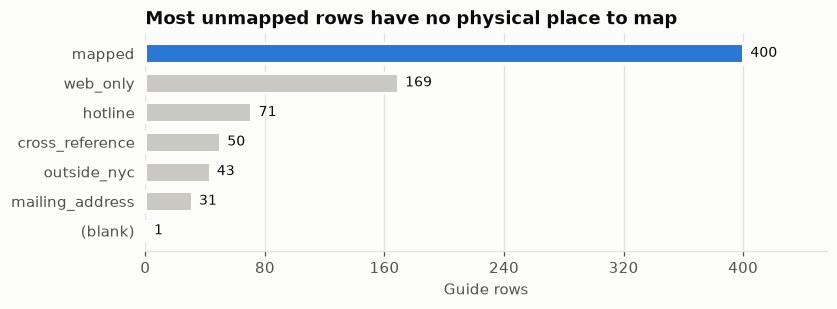

**400** of 765 rows have a physical site. Those rows sit at **333** distinct locations, because one address can list several programs. The rows roll up to **465** parent organizations (rough grouping), of which **249** have at least one mapped row.

In [2]:
rt = nypl.row_type.value_counts()
fig, ax = plt.subplots(figsize=(7.5, 2.7))
hbar(ax, rt.index.tolist(), rt.values.tolist(), color=[BLUE if t == "mapped" else NEUTRAL for t in rt.index])
ax.set_title("Most unmapped rows have no physical place to map")
ax.set_xlabel("Guide rows")
plt.show()

parents_with_site = set(parents.loc[parents.n_mapped.astype(int) > 0, "parent"])
say(f"**{rt['mapped']}** of {len(nypl)} rows have a physical site. Those rows sit at **{mapped.xy_key.nunique()}** distinct locations, "
    f"because one address can list several programs. The rows roll up to **{len(parents)}** parent organizations "
    f"(rough grouping), of which **{len(parents_with_site)}** have at least one mapped row.")

## 2. Where the guide is thin

Raw counts favour large boroughs, so this divides by population and then measures distance. A neighbourhood counts as covered when a guide site lies within the PRD's walking catchment.

Cells are 400 m squares containing at least one FacDB facility. FacDB is an official city list, so unlike OSM its density doesn't depend on volunteers. It is a rough stand-in for developed areas.

,guide rows,distinct locations,population,locations per 100k,share of guide locations,share of population
boro,,,,,,
Manhattan,198,159,1694251,9.4,48.0,19.0
Brooklyn,86,68,2736074,2.5,20.0,31.0
Bronx,58,55,1472654,3.7,17.0,17.0
Queens,41,36,2405464,1.5,11.0,27.0
Staten Island,17,15,495747,3.0,5.0,6.0


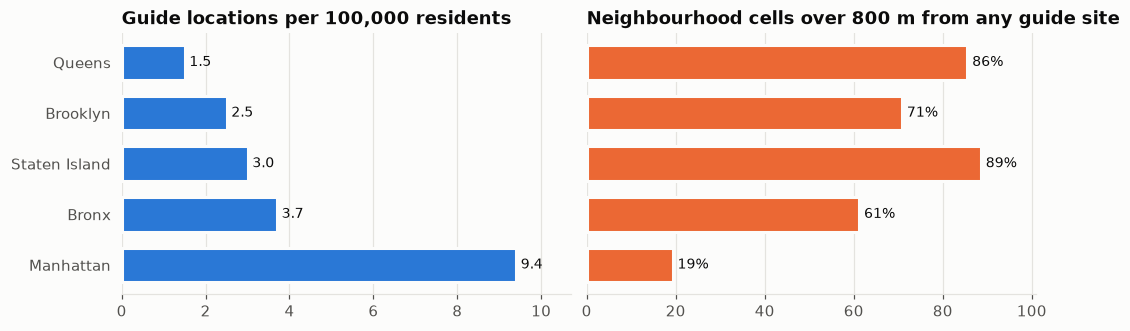

Manhattan has **19%** of residents and **48%** of guide locations. Brooklyn has **2.5** locations per 100k against Manhattan's **9.4**. The lowest rate is **Queens**, at **1.5**. Citywide, **71%** of cells are over 800 m from any guide site.

In [3]:
sites = pd.DataFrame({
    "guide rows": mapped.boro.value_counts(),
    "distinct locations": mapped.groupby("boro").xy_key.nunique(),
}).reindex(BOROUGHS)
sites["population"] = pd.Series(POPULATION)
sites["locations per 100k"] = (sites["distinct locations"] / sites.population * 1e5).round(1)
sites["share of guide locations"] = (sites["distinct locations"] / sites["distinct locations"].sum() * 100).round(0)
sites["share of population"] = (sites.population / sites.population.sum() * 100).round(0)
display(sites)

fac = read(SUP / "facdb.csv", usecols=["lat", "lon", "borough"])
fac["boro"] = norm_borough(fac.borough)
fac = fac[(fac.lat != "") & (fac.lon != "") & (fac.boro != "")]
fac_xy = to_xy(fac.lat.astype(float).to_numpy(), fac.lon.astype(float).to_numpy())
cells = pd.DataFrame({"ix": np.floor(fac_xy[:, 0] / GRID_M).astype(int), "iy": np.floor(fac_xy[:, 1] / GRID_M).astype(int), "boro": fac.boro.values})
cells = cells.groupby(["ix", "iy"]).boro.agg(lambda s: s.value_counts().index[0]).reset_index()
cell_xy = (cells[["ix", "iy"]].to_numpy() + 0.5) * GRID_M
nypl_xy = to_xy(mapped.lat.to_numpy(), mapped.lon.to_numpy())
cells["to_guide_m"] = nearest_m(cell_xy, nypl_xy)
cells["gap"] = cells.to_guide_m > CATCHMENT_M

far = cells.groupby("boro").gap.mean().reindex(BOROUGHS).mul(100)
order = sites["locations per 100k"].sort_values().index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(9.5, 2.9))
hbar(axes[0], order, sites.loc[order, "locations per 100k"].tolist(), fmt="{:.1f}")
axes[0].set_title("Guide locations per 100,000 residents")
hbar(axes[1], order, far[order].tolist(), color=ORANGE, fmt="{:.0f}%")
axes[1].set_title(f"Neighbourhood cells over {CATCHMENT_M} m from any guide site")
axes[1].set_yticklabels([])
plt.show()

m_rate, b_rate, low = sites.loc["Manhattan", "locations per 100k"], sites.loc["Brooklyn", "locations per 100k"], order[0]
say(f"Manhattan has **{sites.loc['Manhattan', 'share of population']:.0f}%** of residents and **{sites.loc['Manhattan', 'share of guide locations']:.0f}%** of guide locations. "
    f"Brooklyn has **{b_rate}** locations per 100k against Manhattan's **{m_rate}**. The lowest rate is **{low}**, at **{sites.loc[low, 'locations per 100k']}**. "
    f"Citywide, **{cells.gap.mean() * 100:.0f}%** of cells are over {CATCHMENT_M} m from any guide site.")

### Gaps by service type

The more useful view for a caseworker: how much of each borough is out of walking range of a guide site offering a given service type? A service can be well covered overall and still be missing in one borough.

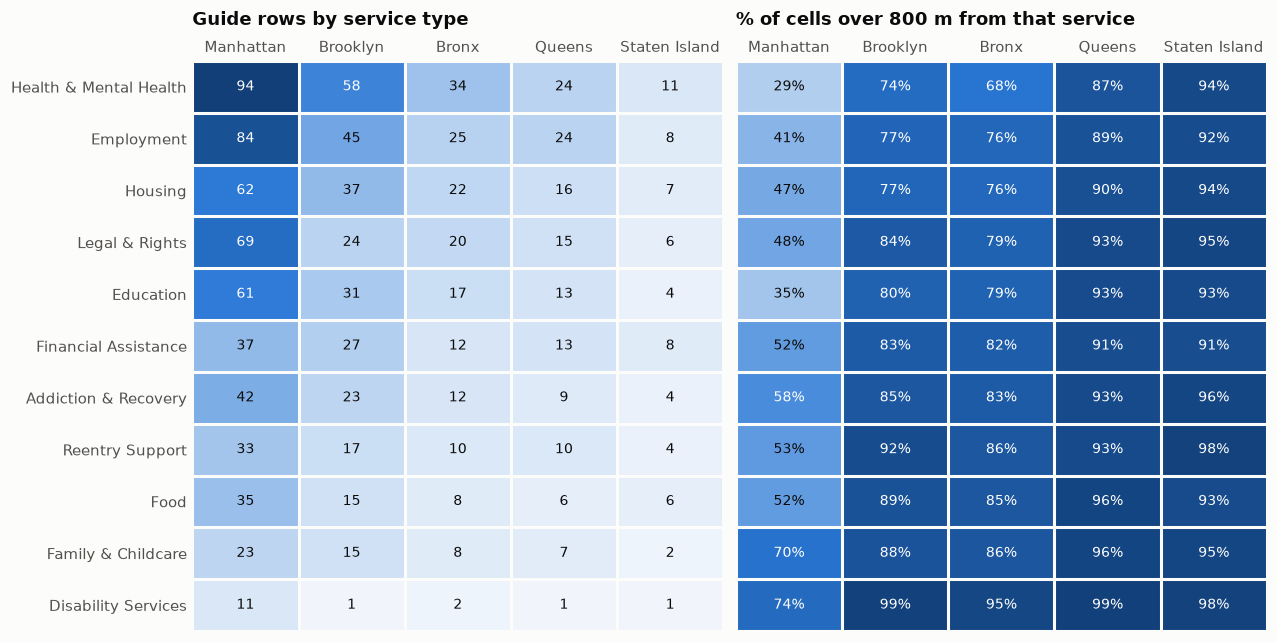

Rows can carry several service types, so the rows on the left add up to more than 400. **0** service-and-borough pairs have no guide site at all. Brooklyn's widest gaps are Disability Services (99% of cells), Reentry Support (92% of cells), Food (89% of cells).

In [4]:
def parse_types(text):
    return [t.strip().strip('"') for t in re.findall(r'"[^"]+"|[^,{}]+', text)]

mapped["types"] = mapped.service_types_all.map(parse_types)
exploded = mapped.explode("types")
exploded = exploded[exploded.types.fillna("") != ""]
type_order = exploded.types.value_counts().index.tolist()

counts = pd.crosstab(exploded.types, exploded.boro).reindex(index=type_order, columns=BOROUGHS, fill_value=0)
gap_pct = pd.DataFrame(index=type_order, columns=BOROUGHS, dtype=float)
for t in type_order:
    sub = exploded[exploded.types == t]
    dist = nearest_m(cell_xy, to_xy(sub.lat.to_numpy(), sub.lon.to_numpy()))
    gap_pct.loc[t] = pd.Series(dist > CATCHMENT_M).groupby(cells.boro.values).mean().reindex(BOROUGHS).mul(100).values

fig, axes = plt.subplots(1, 2, figsize=(11.5, 0.42 * len(type_order) + 1.1))
heat(axes[0], counts)
axes[0].set_title("Guide rows by service type", pad=10)
heat(axes[1], gap_pct, fmt="{:.0f}%", vmax=100)
axes[1].set_title(f"% of cells over {CATCHMENT_M} m from that service", pad=10)
axes[1].set_yticklabels([])
plt.show()

none = [(t, b) for t in type_order for b in BOROUGHS if counts.loc[t, b] == 0]
worst = gap_pct.loc[:, ["Brooklyn"]].sort_values("Brooklyn", ascending=False).head(3)
say(f"Rows can carry several service types, so the rows on the left add up to more than {len(mapped)}. "
    f"**{len(none)}** service-and-borough pairs have no guide site at all"
    + (": " + "; ".join(f"{t} in {b}" for t, b in none) if none else "")
    + ". Brooklyn's widest gaps are " + ", ".join(f"{t} ({v:.0f}% of cells)" for t, v in worst.Brooklyn.items()) + ".")

## 3. What OSM holds

OSM is a general map, not a services directory, so much of the pull is unrelated to KAVI's work. It was pulled broadly on purpose, so that matching wouldn't be limited by a type filter chosen in advance.

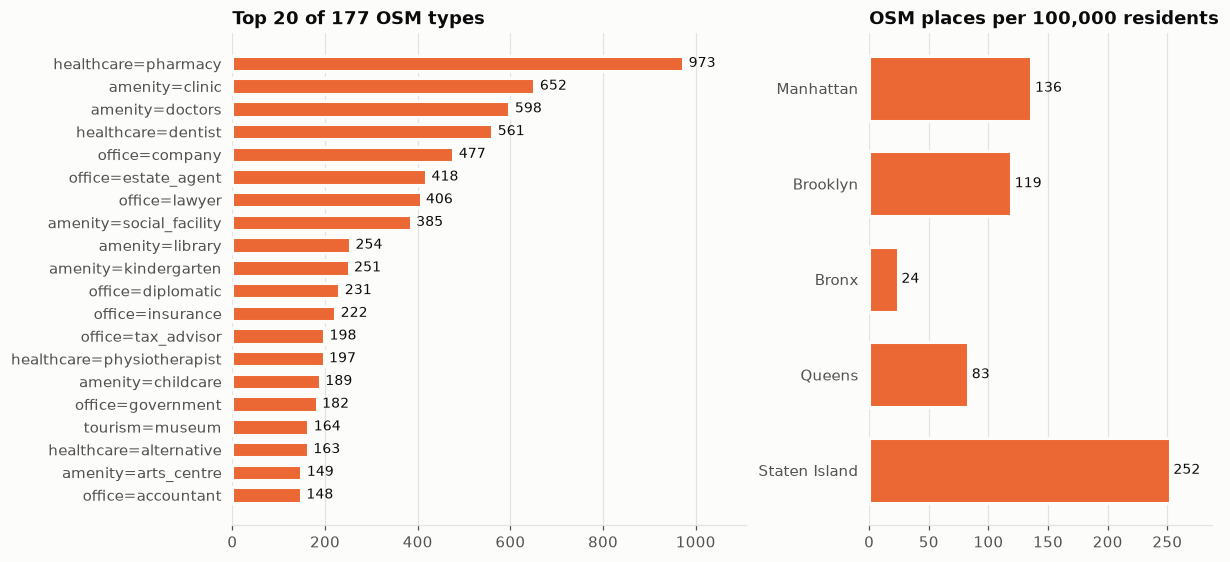

,% of mapped guide rows,% of OSM places
Phone,90,54
Website,96,42
Street address,100,64
Opening hours,no such column,23
Operator,no such column,13


In [5]:
top = osm.primary_type.value_counts().head(20)
per_boro = pd.DataFrame({"OSM places": osm.boro.value_counts()}).reindex(BOROUGHS)
per_boro["per 100k"] = (per_boro["OSM places"] / pd.Series(POPULATION) * 1e5).round(0)

fig, axes = plt.subplots(1, 2, figsize=(11, 5.0), gridspec_kw={"width_ratios": [1.5, 1]})
hbar(axes[0], top.index.tolist(), top.values.tolist(), color=ORANGE)
axes[0].set_title(f"Top 20 of {osm.primary_type.nunique()} OSM types")
hbar(axes[1], per_boro.index.tolist(), per_boro["per 100k"].tolist(), color=ORANGE)
axes[1].set_title("OSM places per 100,000 residents")
plt.show()

fields = {
    "Phone": (nypl.loc[mapped.index, "phone_number"], osm.phone),
    "Website": (nypl.loc[mapped.index, "website"], osm.website),
    "Street address": (nypl.loc[mapped.index, "street"], osm.street),
    "Opening hours": (None, osm.opening_hours),
    "Operator": (None, osm.operator),
}
display(pd.DataFrame({
    "% of mapped guide rows": {k: round((g != "").mean() * 100) if g is not None else "no such column" for k, (g, _) in fields.items()},
    "% of OSM places": {k: round((o != "").mean() * 100) for k, (_, o) in fields.items()},
}))

## 4. How much of the guide OSM matches

Site-level means OSM has the organization, or the building hosting its program, at the guide row's own place. Same building with an unconfirmed organization is shown separately and not counted as a match.

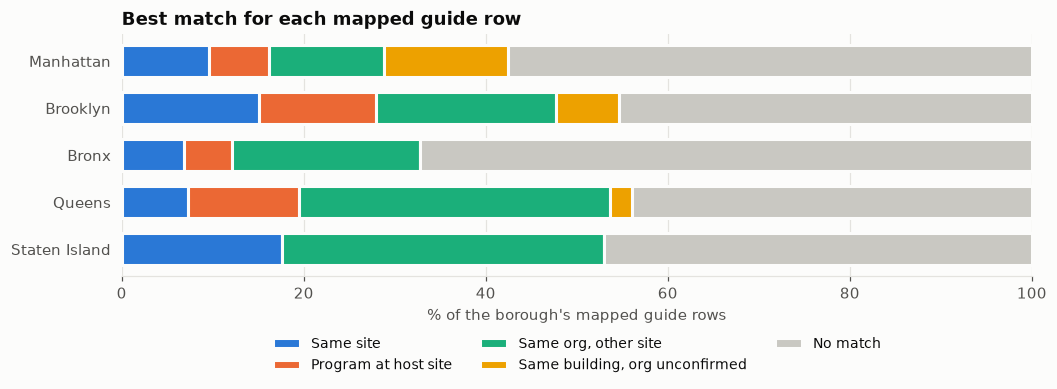

match_class,same_site,program_at_host,same_org_other_site,same_building_unconfirmed,no_match,total
boro,,,,,,
Manhattan,19,13,25,27,114,198
Brooklyn,13,11,17,6,39,86
Bronx,4,3,12,0,39,58
Queens,3,5,14,1,18,41
Staten Island,3,0,6,0,8,17


**74 of 400** mapped rows (18%) match at site level, with another 34 in the same building but unconfirmed. **218 of 765** rows (28%) have the organization somewhere in OSM. By parent organization, **51 of 249** with a mapped row have a site-level match, and **87 of 465** overall are known to OSM.

In [6]:
bmap = best[best.row_type == "mapped"]
n = len(bmap)
site = bmap.match_class.isin(SITE).sum()
org = best.match_class.isin(SITE + ["same_org_other_site"]).sum()
bldg = (bmap.match_class == "same_building_unconfirmed").sum()

by = pd.crosstab(bmap.boro, bmap.match_class).reindex(index=BOROUGHS, columns=CLASSES, fill_value=0)
share = by.div(by.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(9.5, 3.4))
left = np.zeros(len(share))
for c in CLASSES:
    ax.barh(share.index, share[c], left=left, color=CLASS_COLOR[c], edgecolor=SURFACE, linewidth=2, height=0.68, label=CLASS_LABEL[c])
    left += share[c].to_numpy()
ax.invert_yaxis()
ax.tick_params(left=False)
ax.set_xlim(0, 100)
ax.set_xlabel("% of the borough's mapped guide rows")
ax.set_title("Best match for each mapped guide row")
ax.legend(ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=9)
plt.show()
display(by.assign(total=by.sum(axis=1)))

parents_m = parents[parents.n_mapped.astype(int) > 0]
say(f"**{site} of {n}** mapped rows ({pct(site, n)}) match at site level, with another {bldg} in the same building but unconfirmed. "
    f"**{org} of {len(best)}** rows ({pct(org, len(best))}) have the organization somewhere in OSM. "
    f"By parent organization, **{(parents_m.any_site == 'True').sum()} of {len(parents_m)}** with a mapped row have a site-level match, "
    f"and **{(parents.any_org == 'True').sum()} of {len(parents)}** overall are known to OSM.")

### Why rows don't match

These reasons decide what to do next. If the organization simply isn't in OSM, a better matcher can't help. If a named place sits right there but wasn't recognized, it might.

In [7]:
reason_label = {
    "no_named_feature_nearby": "Nothing named nearby in OSM",
    "named_feature_nearby_unrecognized": "Named place nearby, not recognized as the org",
    "org_elsewhere_in_osm_only": "Org in OSM, but at another site",
    "no_physical_site": "No physical site (hotline, web-only and so on)",
    "outside_nyc": "Outside NYC",
    "": "Matched at site level",
}
rs = best.no_match_reason.map(lambda r: reason_label.get(r, r))
tab = pd.crosstab(rs, best.row_type == "mapped").rename(columns={True: "mapped rows", False: "other rows"})
display(tab.sort_values("mapped rows", ascending=False))

miss = bmap[bmap.no_match_reason == "named_feature_nearby_unrecognized"].copy()
miss["nearest_feature_m"] = pd.to_numeric(miss.nearest_feature_m, errors="coerce")
if len(miss):
    say(f"**{len(miss)}** mapped rows have a named OSM place nearby that the matcher did not accept. **{bldg}** of them share a building with it "
        f"and are the same-building rows above. For the rest, the median distance is {miss[miss.match_class == 'no_match'].nearest_feature_m.median():.0f} m. "
        "These haven't been reviewed, so it's unknown how many are real misses and how many are just neighbours in a dense city.")

row_type,other rows,mapped rows
no_match_reason,,
Nothing named nearby in OSM,0,142
"Named place nearby, not recognized as the org",0,110
Matched at site level,0,74
"Org in OSM, but at another site",0,74
"No physical site (hotline, web-only and so on)",322,0
Outside NYC,43,0


**110** mapped rows have a named OSM place nearby that the matcher did not accept. **34** of them share a building with it and are the same-building rows above. For the rest, the median distance is 28 m. These haven't been reviewed, so it's unknown how many are real misses and how many are just neighbours in a dense city.

## 5. Would the old OSM type filter have lost matches?

The first OSM script (`osm_resources_nyc.ts`, since removed) pulled a fixed set of tags: social facilities, food banks, counselling, childcare, employment agencies and community centres. This tests that filter against the places the guide's rows actually match.

In [8]:
def in_old_filter(t):
    return (
        t.get("amenity") in {"social_facility", "food_bank", "childcare", "kindergarten", "community_centre", "social_centre"}
        or t.get("healthcare") in {"counselling", "psychotherapist"}
        or t.get("office") == "employment_agency"
    )

osm["old_filter"] = osm.tags.map(in_old_filter)
OLD_FILTER_TYPES = {
    "amenity=social_facility", "amenity=food_bank", "amenity=childcare", "amenity=kindergarten", "amenity=community_centre",
    "amenity=social_centre", "healthcare=counselling", "healthcare=psychotherapist", "office=employment_agency",
}
tagged = best.merge(osm[["source_id", "old_filter", "primary_type"]], on="source_id", how="left")
site_rows = tagged[tagged.match_class.isin(SITE)]
kept = site_rows.old_filter.fillna(False).astype(bool).sum()

by_type = osm.primary_type.value_counts().rename("OSM places").to_frame()
by_type["site-level matches"] = site_rows.primary_type.value_counts().reindex(by_type.index).fillna(0).astype(int)
by_type["per 100 places"] = (by_type["site-level matches"] / by_type["OSM places"] * 100).round(1)
hits = by_type[by_type["site-level matches"] > 0].sort_values("site-level matches", ascending=False)
display(hits)

CANDIDATE_TYPES = set(by_type.index[by_type["site-level matches"] >= MIN_SITE_MATCHES])
osm["candidate"] = osm.primary_type.isin(CANDIDATE_TYPES)
say(f"The old filter keeps **{osm.old_filter.sum():,}** of {len(osm):,} places but only **{kept} of {len(site_rows)}** site-level matches. "
    f"The other **{len(site_rows) - kept}** would have been lost before matching started. "
    f"Types with no matches account for **{by_type.loc[by_type['site-level matches'] == 0, 'OSM places'].sum():,}** places.")

,OSM places,site-level matches,per 100 places
primary_type,,,
amenity=library,254,17,6.7
amenity=social_facility,385,13,3.4
office=association,83,8,9.6
office=government,182,5,2.7
amenity=college,52,5,9.6
amenity=clinic,652,5,0.8
amenity=hospital,88,4,4.5
office=ngo,44,4,9.1
amenity=community_centre,145,3,2.1


The old filter keeps **1,104** of 9,166 places but only **19 of 74** site-level matches. The other **55** would have been lost before matching started. Types with no matches account for **5,937** places.

## 6. What matched places add, and whether they agree

Only `same_site` rows are compared. A `program_at_host` record describes the host, so its phone and hours aren't the program's.

Phone and website agreement is **biased upward**, because the matcher uses those fields as evidence. Hours can't be checked here, because the guide has no hours column.

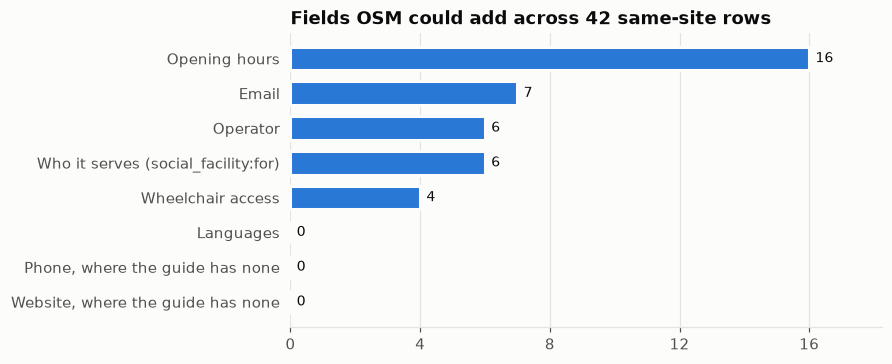

,both present,agree,% agree
Phone,28,22,79.0
Website domain,31,29,94.0
House number,33,32,97.0


Median OSM record among these rows was last edited **2.9 years** ago, and 29% are over 5 years old. A disagreement doesn't show which side is wrong: a phone difference can simply be a main line against a program line.

In [9]:
same = best[best.match_class == "same_site"].merge(osm, on="source_id", how="left", suffixes=("", "_osm")).merge(
    nypl[["id", "phone_number", "website", "street_number"]].rename(columns={"website": "guide_website"}), on="id", how="left")

def has_tag(t, *keys):
    return any(t.get(k) for k in keys)

adds = {
    "Opening hours": same.opening_hours != "",
    "Wheelchair access": same.tags.map(lambda t: has_tag(t, "wheelchair")),
    "Email": same.tags.map(lambda t: has_tag(t, "email", "contact:email")),
    "Operator": same.operator != "",
    "Who it serves (social_facility:for)": same.tags.map(lambda t: has_tag(t, "social_facility:for")),
    "Languages": same.tags.map(lambda t: any(k.startswith("language:") for k in t)),
    "Phone, where the guide has none": (same.phone != "") & (same.phone_number == ""),
    "Website, where the guide has none": (same.website != "") & (same.guide_website == ""),
}
add_tab = pd.Series({k: int(v.sum()) for k, v in adds.items()}).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 3.2))
hbar(ax, add_tab.index.tolist(), add_tab.values.tolist())
ax.set_title(f"Fields OSM could add across {len(same)} same-site rows")
plt.show()

def agreement(left, right):
    both = (left != "") & (right != "")
    return {"both present": int(both.sum()), "agree": int((left[both] == right[both]).sum())}

ages = (pd.Timestamp.now(tz="UTC") - pd.to_datetime(same.last_edit, utc=True, errors="coerce")).dt.days / 365.25
agree = pd.DataFrame({
    "Phone": agreement(same.phone_number.map(digits10), same.phone.map(digits10)),
    "Website domain": agreement(same.guide_website.map(web_domain), same.website.map(web_domain)),
    "House number": agreement(same.street_number.map(first_number), same.house_number.map(first_number)),
}).T
agree["% agree"] = (agree.agree / agree["both present"] * 100).round(0)
display(agree)
say(f"Median OSM record among these rows was last edited **{ages.median():.1f} years** ago, and {pct((ages > 5).sum(), ages.notna().sum())} are over 5 years old. "
    "A disagreement doesn't show which side is wrong: a phone difference can simply be a main line against a program line.")

## 7. OSM places in the guide's gaps

This is the main reason to use OSM: are there plausible places where the guide has nothing nearby?

Candidates are OSM places whose type has at least two site-level matches in section 5. Types are a blunt test, and this list isn't ready for review, so no individual places are listed here. Relevance scoring and a review list come next.

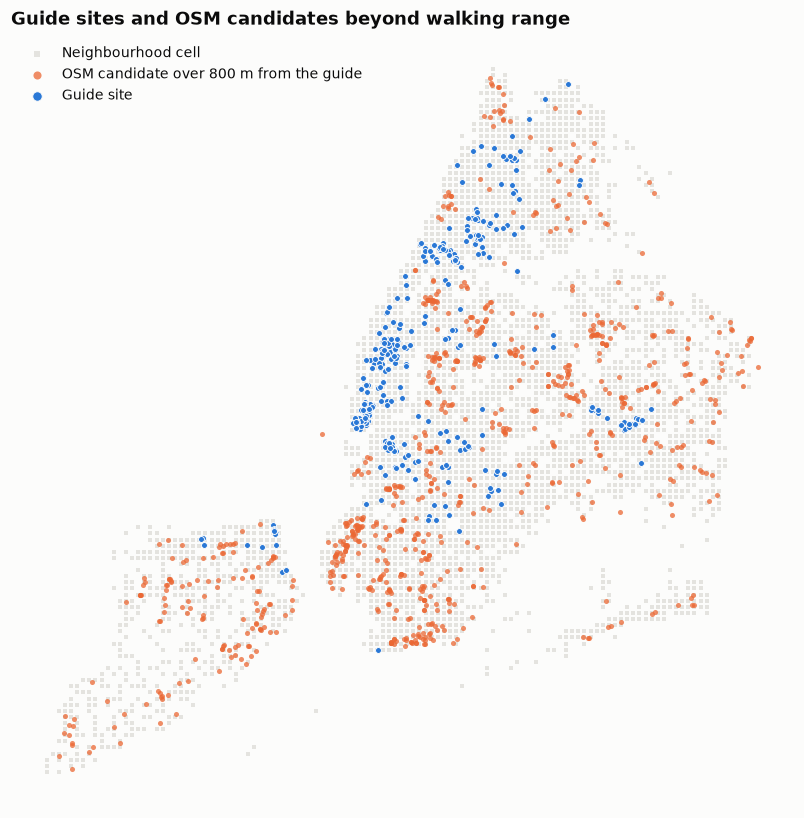

,candidates,in guide gap,all gap cells,gap cells with a candidate,% of gap cells reached
boro,,,,,
Manhattan,538,44,76,53,70.0
Brooklyn,591,314,703,616,88.0
Bronx,143,54,343,236,69.0
Queens,390,295,1024,775,76.0
Staten Island,173,138,450,328,73.0


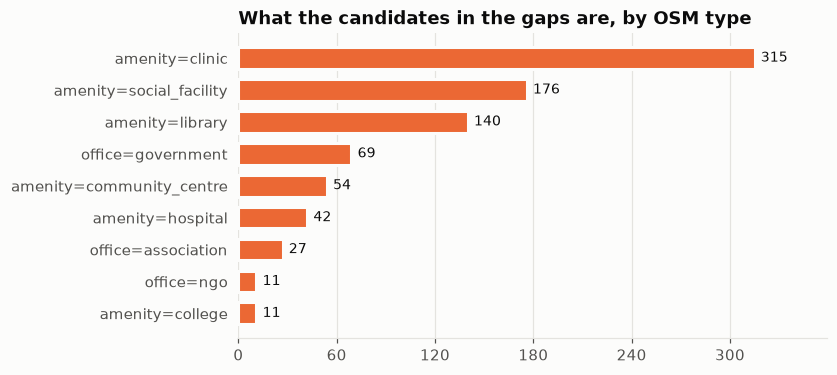

**845** candidates are over 800 m from any guide site, and they would bring **2,008 of 2,596** gap cells within range. That is an upper limit, because it assumes every candidate is relevant. Any type-based list includes places a caseworker wouldn't refer to.

In [10]:
osm_xy = to_xy(osm.lat.to_numpy(), osm.lon.to_numpy())
osm["to_guide_m"] = nearest_m(osm_xy, nypl_xy)
osm["in_gap"] = osm.to_guide_m > CATCHMENT_M
matched_ids = set(best.loc[best.match_class.isin(SITE), "source_id"])
cand = osm[osm.candidate & ~osm.source_id.isin(matched_ids)]
gap_cand = cand[cand.in_gap]

fig, ax = plt.subplots(figsize=(7.2, 7.6))
ax.scatter(cell_xy[:, 0] / 1000, cell_xy[:, 1] / 1000, s=5, color=GRID, marker="s", linewidths=0, label="Neighbourhood cell", zorder=1)
g = to_xy(gap_cand.lat.to_numpy(), gap_cand.lon.to_numpy())
ax.scatter(g[:, 0] / 1000, g[:, 1] / 1000, s=11, color=ORANGE, alpha=0.75, linewidths=0, label=f"OSM candidate over {CATCHMENT_M} m from the guide", zorder=2)
ax.scatter(nypl_xy[:, 0] / 1000, nypl_xy[:, 1] / 1000, s=15, color=BLUE, edgecolor=SURFACE, linewidths=0.6, label="Guide site", zorder=3)
ax.set_aspect("equal")
ax.grid(False)
ax.set_xticks([])
ax.set_yticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title("Guide sites and OSM candidates beyond walking range")
ax.legend(loc="upper left", markerscale=1.6, fontsize=9)
plt.show()

gc = pd.DataFrame({
    "candidates": cand.boro.value_counts(),
    "in guide gap": gap_cand.boro.value_counts(),
    "all gap cells": cells[cells.gap].boro.value_counts(),
    "gap cells with a candidate": 0,
}).reindex(BOROUGHS).fillna(0).astype(int)
gap_cells = cells[cells.gap].reset_index(drop=True)
reach = nearest_m((gap_cells[["ix", "iy"]].to_numpy() + 0.5) * GRID_M, g) <= CATCHMENT_M
gc["gap cells with a candidate"] = pd.Series(reach).groupby(gap_cells.boro).sum().reindex(BOROUGHS).fillna(0).astype(int)
gc["% of gap cells reached"] = (gc["gap cells with a candidate"] / gc["all gap cells"] * 100).round(0)
display(gc)

top_gap = gap_cand.primary_type.value_counts().head(10)
fig, ax = plt.subplots(figsize=(7.5, 3.3))
hbar(ax, top_gap.index.tolist(), top_gap.values.tolist(), color=ORANGE)
ax.set_title("What the candidates in the gaps are, by OSM type")
plt.show()
say(f"**{len(gap_cand):,}** candidates are over {CATCHMENT_M} m from any guide site, and they would bring **{reach.sum():,} of {len(gap_cells):,}** gap cells within range. "
    "That is an upper limit, because it assumes every candidate is relevant. Any type-based list includes places a caseworker wouldn't refer to.")

## 8. How the other sources compare

**OSM completeness.** Licensed childcare and state-listed mental health programs provide a reference that doesn't depend on volunteers. The ratio shows how much of each list OSM has, and whether that varies by borough. The official lists can include several programs at one site, so these are rough ratios, not coverage rates.

**Other sources.** This shows what each source holds. Section 9 shows what it adds to the guide.

In [11]:
files = sorted(p.stem for p in SUP.glob("*.csv") if not re.match(r"(matches_|coverage_|parent_orgs_|nypl_|supplement_|crawl_|review_|ranker_|guide_)", p.stem))
cols = ["source_id", "lat", "borough", "primary_type", "phone", "website", "opening_hours"]
src = {f: read(SUP / f"{f}.csv", usecols=cols) for f in files}
overview = pd.DataFrame({f: {
    "rows": len(d),
    "% with coordinates": round((d.lat != "").mean() * 100),
    "% with phone": round((d.phone != "").mean() * 100),
    "% with website": round((d.website != "").mean() * 100),
    "% with hours": round((d.opening_hours != "").mean() * 100),
} for f, d in src.items()}).T.sort_values("rows", ascending=False)
display(overview)
display(pd.DataFrame({f: norm_borough(d.borough).value_counts().reindex(BOROUGHS).fillna(0).astype(int) for f, d in src.items()}).T.loc[overview.index])

ref = pd.DataFrame({
    "OSM childcare": osm[osm.tags.map(lambda t: t.get("amenity") in {"childcare", "kindergarten"})].boro.value_counts(),
    "licensed childcare (DOHMH)": norm_borough(src["doh_childcare"].borough).value_counts(),
    "OSM mental health": osm[osm.tags.map(lambda t: t.get("healthcare") in {"counselling", "psychotherapist"})].boro.value_counts(),
    "OMH programs": norm_borough(src["omh"].borough).value_counts(),
}).reindex(BOROUGHS).fillna(0).astype(int)
ref["childcare ratio %"] = (ref["OSM childcare"] / ref["licensed childcare (DOHMH)"] * 100).round(0)
ref["mental health ratio %"] = (ref["OSM mental health"] / ref["OMH programs"] * 100).round(0)
display(ref)
hi, lo = ref["childcare ratio %"].idxmax(), ref["childcare ratio %"].idxmin()
say(f"OSM's childcare list is **{ref.loc[hi, 'childcare ratio %']:.0f}%** the size of the licensed list in {hi}, but only **{ref.loc[lo, 'childcare ratio %']:.0f}%** in {lo}. "
    "So OSM's own gaps vary by borough, and thin OSM coverage can't be read as a lack of services.")

,rows,% with coordinates,% with phone,% with website,% with hours
irs_eo,51791,0,0,0,0
facdb,34305,98,0,0,0
osm,9166,100,54,42,23
doh_childcare,2755,100,100,0,0
dycd,2660,98,0,0,0
omh,1931,61,100,0,0
hrsa,491,100,100,48,0
endgbv,286,88,100,98,99
cms_otp,51,84,100,0,0
workforce1,41,100,0,0,100


borough,Manhattan,Brooklyn,Bronx,Queens,Staten Island
irs_eo,21295,16059,4161,8516,1760
facdb,10061,10028,5655,6702,1859
osm,2299,3267,359,1991,1250
doh_childcare,576,1165,325,557,132
dycd,568,843,622,483,144
omh,547,516,434,328,106
hrsa,101,172,155,47,16
endgbv,78,85,47,53,23
cms_otp,21,11,13,4,2
workforce1,9,10,7,10,5


,OSM childcare,licensed childcare (DOHMH),OSM mental health,OMH programs,childcare ratio %,mental health ratio %
Manhattan,55,576,19,547,10.0,3.0
Brooklyn,247,1165,37,516,21.0,7.0
Bronx,6,325,1,434,2.0,0.0
Queens,79,557,5,328,14.0,2.0
Staten Island,53,132,14,106,40.0,13.0


OSM's childcare list is **40%** the size of the licensed list in Staten Island, but only **2%** in Bronx. So OSM's own gaps vary by borough, and thin OSM coverage can't be read as a lack of services.

## 9. Do OSM and the other sources add what the guide lacks?

**Where each source comes from.** Only the NYPL guide is human-verified. The others are not the guide's sources: we fetched them separately, and nobody on this project has reviewed them. The table below is the source's own description, not a quality rating.

| Source | What it is | Reviewed by us |
|---|---|---|
| **NYPL Connections Guide** | Library-curated guide, extracted by `pipeline/` | Source of truth |
| OSM | Volunteer-edited map | No |
| FacDB | NYC planning database of facilities. Partly copies OMH, DYCD, DOHMH and Workforce1, so agreement with those isn't independent | No |
| IRS exempt orgs | Registered nonprofits, usually at a mailing address, so it can only match by organization | No |
| OMH, HRSA, CMS OTP, DOHMH childcare, DYCD, ENDGBV, Workforce1 | Government lists, each covering one kind of service | No |

Every number here counts unreviewed places, so these are upper limits on what a source could add, not what it has added.

In [12]:
supp = read(SUP / "supplement_all.csv", usecols=["source", "source_id", "borough", "lat", "lon", "best_match_class", "matched_nypl_id", "proposed_service_types", "relevance_score", "hitl_review"])
supp["boro"] = norm_borough(supp.borough)
pending = supp[supp.hitl_review == "pending"].copy()
unlocated = int((pending.lat == "").sum())  # pending, but the source gives no coordinates, so left out of distance measures
located = pending[pending.lat != ""].copy()
located["xy_x"], located["xy_y"] = to_xy(located.lat.astype(float).to_numpy(), located.lon.astype(float).to_numpy()).T
located["m_to_guide"] = nearest_m(located[["xy_x", "xy_y"]].to_numpy(), nypl_xy)

SOURCE_ORDER = ["osm", "facdb", "irs_eo", "omh", "hrsa", "doh_childcare", "dycd", "endgbv", "cms_otp", "workforce1"]
guide_found = {}
for s_name in SOURCE_ORDER:
    s_match = read(SUP / f"matches_{s_name}.csv", usecols=["nypl_id", "match_class", "row_type"])
    guide_found[s_name] = s_match[s_match.match_class.isin(SITE) & (s_match.row_type == "mapped")].nypl_id.nunique()
by_source = pd.DataFrame({
    "places": supp.source.value_counts(),
    "mapped guide rows found at site level": pd.Series(guide_found),
    "pending review": pending.source.value_counts(),
    f"pending, over {CATCHMENT_M} m from any guide site": located[located.m_to_guide > CATCHMENT_M].source.value_counts(),
}).reindex(SOURCE_ORDER).fillna(0).astype(int)
display(by_source)

other_found = set().union(*[set(read(SUP / f"matches_{s_name}.csv", usecols=["nypl_id", "match_class", "row_type"]).query("match_class in @SITE and row_type == 'mapped'").nypl_id) for s_name in SOURCE_ORDER if s_name != "osm"])
site_any = other_found | set(read(SUP / "matches_osm.csv", usecols=["nypl_id", "match_class", "row_type"]).query("match_class in @SITE and row_type == 'mapped'").nypl_id)
osm_found = set(read(SUP / "matches_osm.csv", usecols=["nypl_id", "match_class", "row_type"]).query("match_class in @SITE and row_type == 'mapped'").nypl_id)
say(f"Together the sources find **{len(site_any)} of {len(mapped)}** mapped guide rows at site level. OSM finds **{len(osm_found)}**, and only **{len(osm_found - other_found)}** of those are found by no other source. "
    f"OSM supplies **{by_source.loc['osm', 'pending review']} of {len(pending):,}** pending listings, so most of the review list comes from the government lists. {unlocated} pending listings have no coordinates and are left out of the distance measures.")

,places,mapped guide rows found at site level,pending review,"pending, over 800 m from any guide site"
osm,9166,74,208,83
facdb,34305,190,118,34
irs_eo,51791,0,0,0
omh,1931,52,606,241
hrsa,491,14,317,118
doh_childcare,2755,5,195,100
dycd,2660,47,41,15
endgbv,286,9,176,66
cms_otp,51,6,24,3
workforce1,41,0,0,0


Together the sources find **224 of 400** mapped guide rows at site level. OSM finds **74**, and only **23** of those are found by no other source. OSM supplies **208 of 1,685** pending listings, so most of the review list comes from the government lists. 26 pending listings have no coordinates and are left out of the distance measures.

,gap cells,reached by other sources,reached by OSM,reached only by OSM
boro,,,,
Manhattan,76,60,42,4
Brooklyn,703,557,302,24
Bronx,343,220,67,16
Queens,1024,592,167,15
Staten Island,450,130,41,9


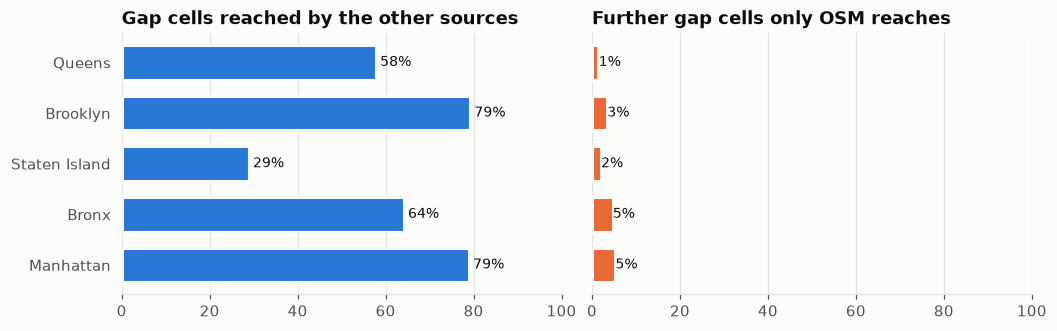

Pending places from the other sources would bring **1,559 of 2,596** gap cells within 800 m if all of them proved relevant. OSM reaches **619**, but only **68** of those are out of reach of the other sources. That is OSM's unique contribution to the gaps.

In [13]:
gap_cells_all = cells[cells.gap].reset_index(drop=True)
gap_xy = (gap_cells_all[["ix", "iy"]].to_numpy() + 0.5) * GRID_M


def reached(frame):
    return nearest_m(gap_xy, frame[["xy_x", "xy_y"]].to_numpy()) <= CATCHMENT_M


osm_hit, other_hit = reached(located[located.source == "osm"]), reached(located[located.source != "osm"])
cover = pd.DataFrame({
    "gap cells": gap_cells_all.boro.value_counts(),
    "reached by other sources": pd.Series(other_hit).groupby(gap_cells_all.boro).sum(),
    "reached by OSM": pd.Series(osm_hit).groupby(gap_cells_all.boro).sum(),
    "reached only by OSM": pd.Series(osm_hit & ~other_hit).groupby(gap_cells_all.boro).sum(),
}).reindex(BOROUGHS).fillna(0).astype(int)
display(cover)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 2.9))
gap_order = [b_name for b_name in order]
hbar(axes[0], gap_order, (cover.loc[gap_order, "reached by other sources"] / cover.loc[gap_order, "gap cells"] * 100).tolist(), fmt="{:.0f}%")
axes[0].set_title("Gap cells reached by the other sources")
hbar(axes[1], gap_order, (cover.loc[gap_order, "reached only by OSM"] / cover.loc[gap_order, "gap cells"] * 100).tolist(), color=ORANGE, fmt="{:.0f}%")
axes[1].set_title("Further gap cells only OSM reaches")
axes[1].set_yticklabels([])
for ax_ in axes:
    ax_.set_xlim(0, 100)
plt.show()

osm_only_total, osm_total = int(cover["reached only by OSM"].sum()), int(cover["reached by OSM"].sum())
say(f"Pending places from the other sources would bring **{int(cover['reached by other sources'].sum()):,} of {int(cover['gap cells'].sum()):,}** gap cells within {CATCHMENT_M} m if all of them proved relevant. "
    f"OSM reaches **{osm_total:,}**, but only **{osm_only_total:,}** of those are out of reach of the other sources. That is OSM's unique contribution to the gaps.")

### Does that close the service gaps?

A nearby place only helps if it offers the missing service. This repeats section 2's measure, adding pending places under the service type proposed for them. Proposed types come from the source's own type and from keywords, so they are unreviewed too.

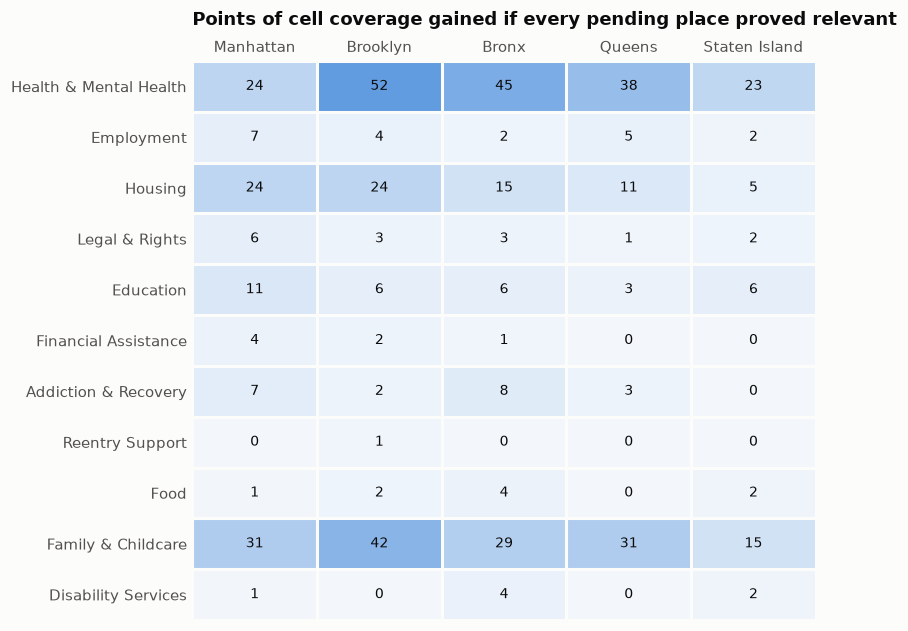

,pending listings proposed
Health & Mental Health,1138
Employment,54
Housing,107
Legal & Rights,34
Education,86
Financial Assistance,11
Addiction & Recovery,36
Reentry Support,1
Food,10
Family & Childcare,288


The gain is concentrated. In Brooklyn the most coverage is added for **Health & Mental Health** (52 points). Its three widest gaps, Disability Services (0), Reentry Support (1), Food (2) gain much less. **Health & Mental Health** accounts for 1,138 of 1,769 proposed types, because the government lists are mostly health providers.

In [14]:
located["ptypes"] = located.proposed_service_types.map(lambda s_: [t.strip() for t in s_.split(";") if t.strip()])
pending_exp = located.explode("ptypes").dropna(subset=["ptypes"])
closed = pd.DataFrame(index=type_order, columns=BOROUGHS, dtype=float)
type_sites = pd.Series({t: pending_exp[pending_exp.ptypes == t].shape[0] for t in type_order}, name="pending listings proposed")
for t in type_order:
    g_sub = exploded[exploded.types == t]
    p_sub = pending_exp[pending_exp.ptypes == t]
    both = np.vstack([to_xy(g_sub.lat.to_numpy(), g_sub.lon.to_numpy()), p_sub[["xy_x", "xy_y"]].to_numpy()])
    still = pd.Series(nearest_m(cell_xy, both) > CATCHMENT_M).groupby(cells.boro.values).mean().reindex(BOROUGHS).mul(100)
    closed.loc[t] = (gap_pct.loc[t] - still).values

fig, ax = plt.subplots(figsize=(7.4, 0.42 * len(type_order) + 1.0))
heat(ax, closed, fmt="{:.0f}", vmax=100)
ax.set_title("Points of cell coverage gained if every pending place proved relevant", pad=10)
plt.show()
display(type_sites.to_frame())

bk_after = closed.Brooklyn.sort_values(ascending=False)
thin_types = gap_pct.Brooklyn.sort_values(ascending=False).head(3).index.tolist()
say(f"The gain is concentrated. In Brooklyn the most coverage is added for **{bk_after.index[0]}** ({bk_after.iloc[0]:.0f} points). Its three widest gaps, " + ", ".join(f"{t} ({closed.loc[t, 'Brooklyn']:.0f})" for t in thin_types) + " gain much less. "
    f"**{type_sites.idxmax()}** accounts for {type_sites.max():,} of {type_sites.sum():,} proposed types, because the government lists are mostly health providers.")

### The review list

`review_recommendations.py` collapses pending listings to one row per place and puts sparse areas first. Priority says where a place would help *if* it proves relevant, not whether it is relevant. Reviewers record verdicts in the file, and rebuilds keep them.

- `review_queue.csv` is committed. It holds OSM, OMH, HRSA and CMS rows only.
- `review_queue_local.csv` stays local. It holds rows from NYC Open Data, whose Terms of Use we haven't read yet; every survivor service and shelter, even those with a public address; and private practices only OSM lists, which may name a person.
- Listings with one name at one address count as one place, so a reviewer judges each place once.
- `map.html` shows this list next to what each source adds to the guide, by area of support.

In [15]:
queue = pd.concat([read(SUP / "review_queue.csv").assign(file="committed"), read(SUP / "review_queue_local.csv").assign(file="local")])
display(pd.crosstab(queue.priority, queue.borough.replace({"The Bronx": "Bronx"})).reindex(columns=order))
display(pd.crosstab(queue.priority, queue.file))
first = queue[(queue.file == "committed") & queue.priority.str.startswith("1") & queue.borough.isin(order[:2])]
display(first.source.value_counts().to_frame("first batch, by source shown"))
say(f"Suggested first batch: priority 1 in {order[0]} and {order[1]}, the two thinnest boroughs, which is **{len(first)}** committed rows of **{len(queue):,}** places. "
    "Expect false positives. Reading a sample shows hospitals, school-based health centres and day cares among the plausible referrals, and the score doesn't separate them.")

borough,Queens,Brooklyn,Staten Island,Bronx,Manhattan
priority,,,,,
1_no_guide_site_nearby,133,196,28,45,28
2_service_missing_nearby,19,31,9,29,33
3_already_covered,33,140,12,115,191
4_no_location,3,8,2,4,6


file,committed,local
priority,,
1_no_guide_site_nearby,278,152
2_service_missing_nearby,65,56
3_already_covered,360,131
4_no_location,3,20


,"first batch, by source shown"
source,
hrsa,81
omh,78
osm,54
cms_otp,1


Suggested first batch: priority 1 in Queens and Brooklyn, the two thinnest boroughs, which is **214** committed rows of **1,065** places. Expect false positives. Reading a sample shows hospitals, school-based health centres and day cares among the plausible referrals, and the score doesn't separate them.

## 10. How well the relevance score ranks places

**How to read this.** AUC is the chance that a labelled place outranks an unlabelled one, and 0.5 is a coin flip. Unlabelled places aren't known to be irrelevant, so this isn't precision or recall. The baseline knows only each place's source and type, learned on held-out folds. If the score doesn't beat it, the extra signals aren't adding much.

- **First, against the guide.** Label: the place matches a guide site. This is the only human-reviewed label, but it can only show that the score finds places like those already in the guide.
- **Then, against the other sources.** Label: another service-focused list has the same place. FacDB and OSM don't count as labels, because they are general. Corroboration is removed from the score for this test, or it would be circular.

Sources with fewer than 20 labelled places appear in the table but not the chart.

**Against the guide**

,places,positives,score_auc,baseline_auc,score minus baseline
source,,,,,
all but irs_eo,51686,574,0.794,0.783,0.011
osm,9166,64,0.828,0.788,0.040
facdb,34305,324,0.802,0.774,0.028
omh,1931,80,0.757,0.798,-0.041
doh_childcare,2755,4,0.354,0.186,0.168
dycd,2660,74,0.544,0.641,-0.097
endgbv,286,9,0.362,0.125,0.237
workforce1,41,0,NaN,NaN,NaN
hrsa,491,13,0.549,0.391,0.158


**Against the other service lists**

,places,positives,score_auc,score_without_contact_auc,baseline_auc,score minus baseline
source,,,,,,
all but irs_eo,51686,3793,0.487,0.495,0.788,-0.301
osm,9166,354,0.803,0.792,0.912,-0.109
facdb,34305,3098,0.488,0.488,0.773,-0.285
omh,1931,107,0.686,0.601,0.743,-0.057
doh_childcare,2755,58,0.485,0.485,0.240,0.245
dycd,2660,107,0.555,0.555,0.499,0.056
endgbv,286,3,0.531,0.531,0.747,-0.216
workforce1,41,0,NaN,NaN,NaN,NaN
hrsa,491,57,0.404,0.404,0.488,-0.084


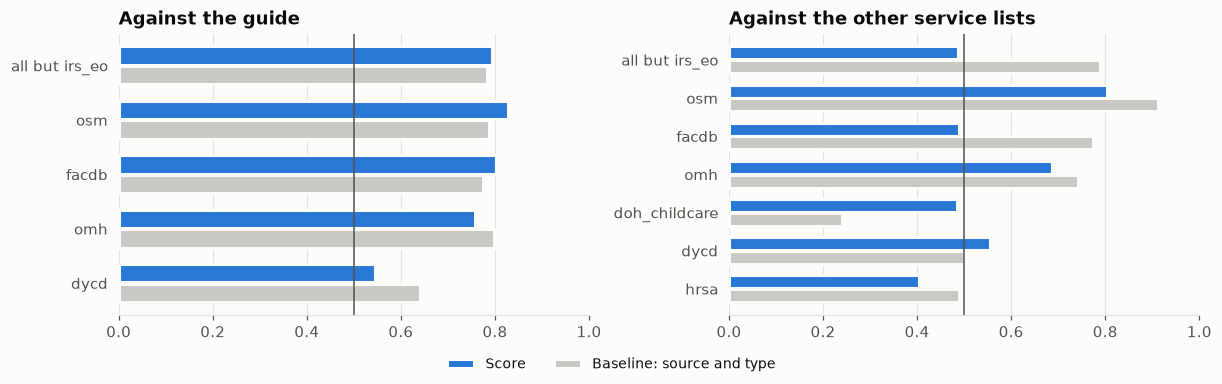

**Against the guide**, the pooled score is 0.794 and the baseline 0.783, and the score beats the baseline in 3 of 5 rows. **Against the other service lists**, the pooled score is 0.487 and the baseline 0.788, and the score beats it in 2 of 7 rows. So most of the ranking power comes from knowing what kind of source and type a place is. The score is a fair way to cut a very long list, but not evidence that a place is relevant, which is why every row still needs a person. The second label has its own weakness: it mostly shows which kinds of place appear on several government lists, such as schools hosting DYCD programs.

In [16]:
rank = read(SUP / "ranker_eval.csv")
for col in ["score_auc", "baseline_auc", "score_without_contact_auc"]:
    rank[col] = pd.to_numeric(rank[col], errors="coerce")
rank["places"], rank["positives"] = rank.places.astype(int), rank.positives.astype(int)
rank["enough"] = rank.enough_positives == "True"
rank["score minus baseline"] = (rank.score_auc - rank.baseline_auc).round(3)
for lab, title in [("guide match", "Against the guide"), ("other service list", "Against the other service lists")]:
    say(f"**{title}**")
    display(rank[rank.label == lab].drop(columns=["label", "enough_positives", "enough"] + (["score_without_contact_auc"] if lab == "guide match" else [])).set_index("source"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for ax_, (lab, title) in zip(axes, [("guide match", "Against the guide"), ("other service list", "Against the other service lists")]):
    part = rank[(rank.label == lab) & rank.enough]
    y_pos = np.arange(len(part))
    ax_.barh(y_pos - 0.18, part.score_auc, height=0.34, color=BLUE, edgecolor=SURFACE, linewidth=2, label="Score")
    ax_.barh(y_pos + 0.18, part.baseline_auc, height=0.34, color=NEUTRAL, edgecolor=SURFACE, linewidth=2, label="Baseline: source and type")
    ax_.set_yticks(y_pos, part.source)
    ax_.invert_yaxis()
    ax_.tick_params(left=False)
    ax_.axvline(0.5, color=MUTED, linewidth=1)
    ax_.set_xlim(0, 1)
    ax_.set_title(title)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=2, fontsize=9)
plt.show()

g_rank = rank[(rank.label == "guide match") & rank.enough].set_index("source")
o_rank = rank[(rank.label == "other service list") & rank.enough].set_index("source")
say(f"**Against the guide**, the pooled score is {g_rank.loc['all but irs_eo', 'score_auc']:.3f} and the baseline {g_rank.loc['all but irs_eo', 'baseline_auc']:.3f}, and the score beats the baseline in {int((g_rank['score minus baseline'] > 0).sum())} of {len(g_rank)} rows. "
    f"**Against the other service lists**, the pooled score is {o_rank.loc['all but irs_eo', 'score_auc']:.3f} and the baseline {o_rank.loc['all but irs_eo', 'baseline_auc']:.3f}, and the score beats it in {int((o_rank['score minus baseline'] > 0).sum())} of {len(o_rank)} rows. "
    "So most of the ranking power comes from knowing what kind of source and type a place is. The score is a fair way to cut a very long list, but not evidence that a place is relevant, which is why every row still needs a person. "
    "The second label has its own weakness: it mostly shows which kinds of place appear on several government lists, such as schools hosting DYCD programs.")

## 11. What a website crawl adds, including events

A pilot crawl visited each site's home page and up to four related pages, obeying robots.txt and rate limits. Text is read by rules, with no LLM. **Group A** is OSM places pending review. **Group B** is guide rows with a site-level OSM match, which gives a benchmark with human-reviewed service types, though these rows are already vetted and aren't a fair comparison for A.

Page text is third-party content, so crawl output isn't committed and nothing from it is printed here beyond counts. The two by-eye checks below are one reader's judgement on the 2026-11-05 run, entered by hand, and are not labels.

In [17]:
if not (SUP / "crawl_pilot.csv").exists():
    crawl, events = None, None
    say("Crawl output not found, so this section is skipped. Run `crawl_sites.py` to create it.")
else:
    crawl, events = read(SUP / "crawl_pilot.csv"), read(SUP / "crawl_events.csv")
    display(pd.crosstab(crawl.site_status, crawl.group))

    live = crawl[crawl.site_status == "live"]
    live_b, live_a = live[live.group == "B"], live[live.group == "A"]
    found_types = live_b.service_types_found.map(lambda s_: {t.strip() for t in s_.split(";") if t.strip()})
    listed_types = live_b.guide_service_types.map(lambda s_: set(parse_types(s_)))
    bench = pd.DataFrame([{"service type": t, "guide lists": sum(t in g_ for g_ in listed_types), "site also shows": sum(t in g_ and t in f_ for g_, f_ in zip(listed_types, found_types)),
                           "site shows, guide doesn't": sum(t in f_ and t not in g_ for g_, f_ in zip(listed_types, found_types))} for t in type_order]).set_index("service type")
    bench["% found"] = (bench["site also shows"] / bench["guide lists"] * 100).round(0)
    display(bench.sort_values("% found", ascending=False))

    enrich = pd.DataFrame({name: {"Group B": (live_b[col] != "").sum(), "Group A": (live_a[col] != "").sum()} for name, col in
                           [("Description", "description"), ("Hours", "hours"), ("Eligibility wording", "eligibility"), ("Referral wording", "referral"), ("Languages", "languages")]}).T
    display(enrich)
    a_any, b_any = (live_a.service_types_found != "").sum(), (live_b.service_types_found != "").sum()
    new_desc = ((live_b.description != "") & (live_b.guide_has_description != "True")).sum()
    say(f"**Relevance.** Site text supports at least one service type on **{a_any} of {len(live_a)}** live OSM places and {b_any} of {len(live_b)} guide rows, so it barely separates anything. Nursing homes match Health and Food, and \"careers\" pages match Employment. "
        f"By eye, words like \"nursing\", \"day care\" and \"private practice\" in descriptions separated noise better, but no such filter has been built or tested.\n\n"
        f"**Enrichment.** Descriptions add little: **{new_desc}** guide rows gain one they lacked. Hours and referral and eligibility wording are the useful additions, though by eye some of these snippets were off-topic. "
        f"**{(live_b.shared_domain == 'True').sum()}** live B rows share a domain with other places, and location-specific details are withheld unless the page names that place.\n\n"
        f"**Possible guide errors.** **{len(read(SUP / 'guide_checks.csv'))}** flags are listed in `guide_checks.csv` for a person to check. They aren't confirmed errors.")

group,A,B
site_status,,
dead,9,2
live,110,47
other_failure,2,5
redirected,2,1
robots_blocked,28,18


,guide lists,site also shows,"site shows, guide doesn't",% found
service type,,,,
Health & Mental Health,30,27,11,90.0
Employment,22,19,20,86.0
Housing,17,13,12,76.0
Education,12,9,12,75.0
Addiction & Recovery,16,10,2,62.0
Food,11,5,6,45.0
Legal & Rights,14,6,3,43.0
Financial Assistance,8,3,6,38.0
Reentry Support,8,2,3,25.0


,Group B,Group A
Description,43,106
Hours,10,41
Eligibility wording,22,63
Referral wording,24,51
Languages,9,10


**Relevance.** Site text supports at least one service type on **106 of 110** live OSM places and 41 of 47 guide rows, so it barely separates anything. Nursing homes match Health and Food, and "careers" pages match Employment. By eye, words like "nursing", "day care" and "private practice" in descriptions separated noise better, but no such filter has been built or tested.

**Enrichment.** Descriptions add little: **0** guide rows gain one they lacked. Hours and referral and eligibility wording are the useful additions, though by eye some of these snippets were off-topic. **9** live B rows share a domain with other places, and location-specific details are withheld unless the page names that place.

**Possible guide errors.** **7** flags are listed in `guide_checks.csv` for a person to check. They aren't confirmed errors.

In [18]:
if events is not None:
    ev = events[events.kind == "event"]
    display(pd.crosstab(ev.timing, ev.group, margins=True))
    display(ev.extraction_detail.value_counts().to_frame("events, by how they were extracted"))
    up = ev[ev.upcoming == "yes"]
    say(f"Of **{len(ev)}** extracted events, **{len(up)}** are upcoming, from **{up.domain.nunique()}** domains out of **{crawl.domain.nunique()}** crawled. A further {(events.kind == 'program').sum()} entries are undated program headings, which are noisy. Only {(ev.extracted == 'structured').sum()} events came from structured data, so nearly all depend on reading page text. "
        "By eye, on an earlier version of the output: 9 of 16 checked events were fully right, 3 had the right date with a poor title, and 4 were wrong. About 10 to 15 of 83 upcoming events were useful to a caseworker. Titles were fixed after that check and accuracy hasn't been re-measured. "
        "**Events aren't ready for the map without a person approving each one.** A map pilot should start from the few sites with dated listings.")

group,A,A+B,B,All
timing,,,,
partial_date,39,0,9,48
past,114,0,23,137
recurring,11,1,4,16
upcoming,16,0,58,74
All,180,1,94,275


,"events, by how they were extracted"
extraction_detail,
text,204
time-tag,56
json-ld,15


Of **275** extracted events, **74** are upcoming, from **10** domains out of **156** crawled. A further 518 entries are undated program headings, which are noisy. Only 15 events came from structured data, so nearly all depend on reading page text. By eye, on an earlier version of the output: 9 of 16 checked events were fully right, 3 had the right date with a poor title, and 4 were wrong. About 10 to 15 of 83 upcoming events were useful to a caseworker. Titles were fixed after that check and accuracy hasn't been re-measured. **Events aren't ready for the map without a person approving each one.** A map pilot should start from the few sites with dated listings.

## 12. Findings

In [19]:
findings = pd.DataFrame({
    "guide locations per 100k": sites["locations per 100k"],
    f"% of cells over {CATCHMENT_M} m from a guide site": far.round(0).astype(int),
    "OSM candidates in those gaps": gc["in guide gap"],
}).loc[order]
display(findings)

no_named = (bmap.no_match_reason == "no_named_feature_nearby").sum()
elsewhere = (bmap.no_match_reason == "org_elsewhere_in_osm_only").sum()
brooklyn_gaps = ", ".join(f"{t} ({v:.0f}%)" for t, v in worst.Brooklyn.items())
missed_types = hits[[t not in OLD_FILTER_TYPES for t in hits.index]].index[:5].tolist()
added = "; ".join(f"{k.lower()} ({v})" for k, v in add_tab.items() if v > 0)
fills = int(adds["Phone, where the guide has none"].sum() + adds["Website, where the guide has none"].sum())

say(f"""
**The guide is thinnest per resident in {order[0]}, then {order[1]}.** {order[0]} has {sites.loc[order[0], 'locations per 100k']} guide locations per 100k residents and {order[1]} {sites.loc[order[1], 'locations per 100k']}, against {m_rate} in Manhattan. Manhattan has {sites.loc['Manhattan', 'share of population']:.0f}% of residents and {sites.loc['Manhattan', 'share of guide locations']:.0f}% of guide locations. Citywide, {cells.gap.mean() * 100:.0f}% of neighbourhood cells are over {CATCHMENT_M} m from any guide site.

**Brooklyn's widest service gaps** are {brooklyn_gaps}, measured as the share of its cells out of walking range of that service.

**OSM matches part of the guide.** {site} of {n} mapped rows ({pct(site, n)}) match at site level, with {bldg} more in the same building but unconfirmed. {org} of {len(best)} rows have the organization somewhere in OSM. These are accepted matches, not measured accuracy.

**Better matching can only help some of the remainder.** For {no_named} mapped rows OSM has nothing named nearby, and {elsewhere} have the organization only at another site. Another {len(miss)} have a named place nearby that wasn't accepted, including the {bldg} same-building rows. Only that last group could improve with better matching, and it hasn't been reviewed.

**The old type filter was too narrow.** It keeps {kept} of {len(site_rows)} site-level matches, so {len(site_rows) - kept} would have been lost before matching started. The types it left out include {", ".join(missed_types)}.

**OSM adds a few fields, not contact details.** Across {len(same)} same-site rows it adds {added}. It fills {fills} missing phones or websites. Where both sources have a value, house numbers agree on {agree.loc['House number', 'agree']} of {agree.loc['House number', 'both present']}, website domains on {agree.loc['Website domain', 'agree']} of {agree.loc['Website domain', 'both present']} and phones on {agree.loc['Phone', 'agree']} of {agree.loc['Phone', 'both present']}. Phone and website agreement is inflated because the matcher uses those fields as evidence.

**OSM could reach many of the gaps, but this is an upper limit.** {len(gap_cand):,} candidates sit over {CATCHMENT_M} m from any guide site. "Candidate" only means the place's OSM type has at least {MIN_SITE_MATCHES} site-level guide matches, so this isn't a review list.

**OSM has its own gaps.** Its childcare list is {ref.loc[hi, 'childcare ratio %']:.0f}% the size of the licensed list in {hi} but only {ref.loc[lo, 'childcare ratio %']:.0f}% in {lo}. Thin OSM coverage doesn't show a lack of services, and places like {lo} probably need official sources more than OSM.

**Other sources add more to the gaps than OSM does.** Without OSM they find {len(other_found)} of {len(mapped)} mapped guide rows at site level, and OSM adds {len(osm_found - other_found)} more. Their pending places reach {int(cover['reached by other sources'].sum()):,} of {int(cover['gap cells'].sum()):,} gap cells, and OSM alone adds {osm_only_total:,} more. All of this is unreviewed and assumes every place proves relevant.

**The widest service gaps stay wide.** Pending places are mostly health providers ({type_sites.max():,} of {type_sites.sum():,} proposed types), so Brooklyn's thinnest services gain little: {", ".join(f"{t} ({closed.loc[t, 'Brooklyn']:.0f})" for t in thin_types)}, in points of cell coverage. A different source would be needed for those, and we have no bulk list of food pantries beyond FacDB or of OASAS and SAMHSA programs.

**The score helps cut the list but doesn't show relevance.** Pooled AUC is {g_rank.loc['all but irs_eo', 'score_auc']:.3f} against the guide (baseline {g_rank.loc['all but irs_eo', 'baseline_auc']:.3f}) and {o_rank.loc['all but irs_eo', 'score_auc']:.3f} against the other service lists (baseline {o_rank.loc['all but irs_eo', 'baseline_auc']:.3f}).

**Next step: human review.** {len(first)} places in {order[0]} and {order[1]} form a first batch. Their verdicts would give the first real relevance labels, and would show whether any supplement deserves to go further.

**Limits**
- Gap cells use FacDB as a rough stand-in for developed areas, so the percentages are indicative rather than exact.
- A nearby place counts as reachable by straight-line distance, and proposed service types are unreviewed.
- NYC Open Data's Terms of Use have not been read, so those rows stay out of committed files. OSM's ODbL licence requires attribution and may apply share-alike to a combined table, so check that before anything reaches the front end.
""")

,guide locations per 100k,% of cells over 800 m from a guide site,OSM candidates in those gaps
boro,,,
Queens,1.5,86,295
Brooklyn,2.5,71,314
Staten Island,3.0,89,138
Bronx,3.7,61,54
Manhattan,9.4,19,44



**The guide is thinnest per resident in Queens, then Brooklyn.** Queens has 1.5 guide locations per 100k residents and Brooklyn 2.5, against 9.4 in Manhattan. Manhattan has 19% of residents and 48% of guide locations. Citywide, 71% of neighbourhood cells are over 800 m from any guide site.

**Brooklyn's widest service gaps** are Disability Services (99%), Reentry Support (92%), Food (89%), measured as the share of its cells out of walking range of that service.

**OSM matches part of the guide.** 74 of 400 mapped rows (18%) match at site level, with 34 more in the same building but unconfirmed. 218 of 765 rows have the organization somewhere in OSM. These are accepted matches, not measured accuracy.

**Better matching can only help some of the remainder.** For 142 mapped rows OSM has nothing named nearby, and 74 have the organization only at another site. Another 110 have a named place nearby that wasn't accepted, including the 34 same-building rows. Only that last group could improve with better matching, and it hasn't been reviewed.

**The old type filter was too narrow.** It keeps 19 of 74 site-level matches, so 55 would have been lost before matching started. The types it left out include amenity=library, office=association, office=government, amenity=college, amenity=clinic.

**OSM adds a few fields, not contact details.** Across 42 same-site rows it adds opening hours (16); email (7); operator (6); who it serves (social_facility:for) (6); wheelchair access (4). It fills 0 missing phones or websites. Where both sources have a value, house numbers agree on 32 of 33, website domains on 29 of 31 and phones on 22 of 28. Phone and website agreement is inflated because the matcher uses those fields as evidence.

**OSM could reach many of the gaps, but this is an upper limit.** 845 candidates sit over 800 m from any guide site. "Candidate" only means the place's OSM type has at least 2 site-level guide matches, so this isn't a review list.

**OSM has its own gaps.** Its childcare list is 40% the size of the licensed list in Staten Island but only 2% in Bronx. Thin OSM coverage doesn't show a lack of services, and places like Bronx probably need official sources more than OSM.

**Other sources add more to the gaps than OSM does.** Without OSM they find 201 of 400 mapped guide rows at site level, and OSM adds 23 more. Their pending places reach 1,559 of 2,596 gap cells, and OSM alone adds 68 more. All of this is unreviewed and assumes every place proves relevant.

**The widest service gaps stay wide.** Pending places are mostly health providers (1,138 of 1,769 proposed types), so Brooklyn's thinnest services gain little: Disability Services (0), Reentry Support (1), Food (2), in points of cell coverage. A different source would be needed for those, and we have no bulk list of food pantries beyond FacDB or of OASAS and SAMHSA programs.

**The score helps cut the list but doesn't show relevance.** Pooled AUC is 0.794 against the guide (baseline 0.783) and 0.487 against the other service lists (baseline 0.788).

**Next step: human review.** 214 places in Queens and Brooklyn form a first batch. Their verdicts would give the first real relevance labels, and would show whether any supplement deserves to go further.

**Limits**
- Gap cells use FacDB as a rough stand-in for developed areas, so the percentages are indicative rather than exact.
- A nearby place counts as reachable by straight-line distance, and proposed service types are unreviewed.
- NYC Open Data's Terms of Use have not been read, so those rows stay out of committed files. OSM's ODbL licence requires attribution and may apply share-alike to a combined table, so check that before anything reaches the front end.


### What we tested and what it improved

Figures marked *fixed* were measured once on 2026-11-05 and are entered by hand, because the earlier state no longer exists to compute from.

In [20]:
tested = pd.DataFrame([
    ("Better OSM matching (phone, website, address, aliases, building ID)", "Yes", f"Site-level matches rose from 61 (fixed) to {site} of {n} mapped rows"),
    ("Dropping the old OSM type filter", "Yes", f"It would have lost {len(site_rows) - kept} of {len(site_rows)} site-level matches"),
    ("OSM values on matched guide rows", "A little", f"Adds {added}. Fills {fills} missing phones or websites"),
    ("OSM places in the guide's gaps", "A little", f"Reaches {osm_only_total:,} gap cells no other pending source reaches, unreviewed"),
    ("Other public sources", "Yes, if review confirms it", f"{len(other_found)} guide rows found without OSM. Reaches {int(cover['reached by other sources'].sum()):,} gap cells, mostly health providers"),
    ("Relevance score from proxy signals", "Barely", f"AUC {g_rank.loc['all but irs_eo', 'score_auc']:.3f} vs baseline {g_rank.loc['all but irs_eo', 'baseline_auc']:.3f} against the guide. Type does most of the work"),
    ("Has a website, as a signal", "Weak", "Within an OSM type, places with a website are 2.6 times likelier to match the guide (fixed). Kept out of the score"),
    ("Crawl, to judge relevance", "No", "Nearly every live site matches some service type"),
    ("Crawl, to enrich records", "Selectively", "Hours and referral wording on sites with their own domain, plus guide checks"),
    ("Crawl, for events", "Not yet", "About 56% of 16 checked events fully right (fixed), and few are relevant"),
], columns=["what we tested", "did it improve things?", "evidence"]).set_index("what we tested")
with pd.option_context("display.max_colwidth", None):
    display(tested)

,did it improve things?,evidence
what we tested,,
"Better OSM matching (phone, website, address, aliases, building ID)",Yes,Site-level matches rose from 61 (fixed) to 74 of 400 mapped rows
Dropping the old OSM type filter,Yes,It would have lost 55 of 74 site-level matches
OSM values on matched guide rows,A little,Adds opening hours (16); email (7); operator (6); who it serves (social_facility:for) (6); wheelchair access (4). Fills 0 missing phones or websites
OSM places in the guide's gaps,A little,"Reaches 68 gap cells no other pending source reaches, unreviewed"
Other public sources,"Yes, if review confirms it","201 guide rows found without OSM. Reaches 1,559 gap cells, mostly health providers"
Relevance score from proxy signals,Barely,AUC 0.794 vs baseline 0.783 against the guide. Type does most of the work
"Has a website, as a signal",Weak,"Within an OSM type, places with a website are 2.6 times likelier to match the guide (fixed). Kept out of the score"
"Crawl, to judge relevance",No,Nearly every live site matches some service type
"Crawl, to enrich records",Selectively,"Hours and referral wording on sites with their own domain, plus guide checks"
